<table>
  <tr>
    <td><div align="left"><font size="30">Chapter 2:<br>Representing position & orientation</font></div></td>
    <td><img src="https://github.com/petercorke/RVC3-python/raw/main/figures/RVC3P-cover.png?raw=1" width="200"></td>
  </tr>
</table>

<span style="font-size:150%">Robotics, Vision & Control 3e: for Python</span>

Copyright © 2021- Peter Corke

In [ ]:
try:
    from google.colab import output
    print('Running on CoLab')
    output.enable_custom_widget_manager()
    !pip install ipympl
    !pip install spatialmath-python
    COLAB = True
    SWIFT = False
except ModuleNotFoundError:
    COLAB = False
    SWIFT = False
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "last_expr_or_assign"

%matplotlib widget

In [ ]:
from IPython.display import HTML

# standard imports
import numpy as np
from scipy import linalg
import matplotlib.pyplot as plt
import math
from math import pi
np.set_printoptions(
    linewidth=120, formatter={
        'float': lambda x: f"{0:8.4g}" if abs(x) < 1e-10 else f"{x:8.4g}"})
np.random.seed(0)
from spatialmath import *
from spatialmath.base import *

There are some minor code changes compared to the book. These are to support 
the Matplotlib widget (ipympl) backend.  This allows 3D plots to be rotated
so the changes are worthwhile.

# 2.1 Foundations


# 2.2 Working in Two Dimensions (2D)


## 2.2.1 Orientation in Two Dimensions


### 2.2.1.1 2D Rotation Matrix


In [3]:
R = rot2(0.3)

array([[  0.9553,  -0.2955],
       [  0.2955,   0.9553]])

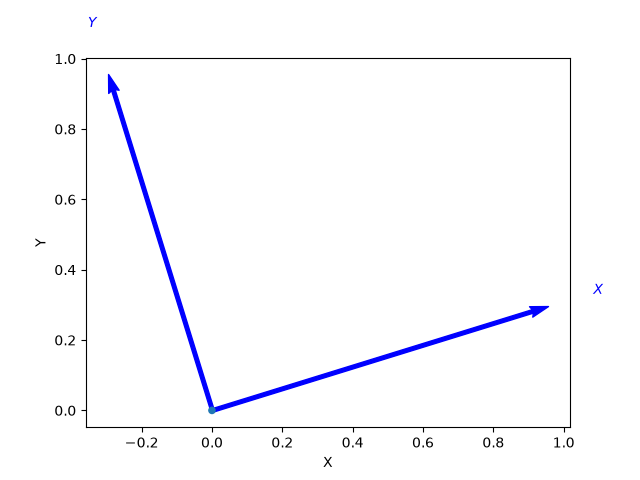

In [4]:
plotvol2(new=True)  # for matplotlib/widget
trplot2(R);

In [5]:
np.linalg.det(R)

np.float64(0.9999999999999999)

In [6]:
np.linalg.det(R @ R) 
# SO(n) is precisely the subgrp of O(n) with det 1

np.float64(0.9999999999999998)

In [7]:
from sympy import Symbol, Matrix, simplify, pprint
theta = Symbol('theta')
R = Matrix(rot2(theta))  # convert to SymPy matrix

Matrix([
[cos(theta), -sin(theta)],
[sin(theta),  cos(theta)]])

In [8]:
simplify(R * R)

Matrix([
[cos(2*theta), -sin(2*theta)],
[sin(2*theta),  cos(2*theta)]])

In [9]:
R.det()

sin(theta)**2 + cos(theta)**2

In [10]:
R.det().simplify()

1

### 2.2.1.2 Matrix Exponential for Rotation


In [11]:
R = rot2(0.3);

In [12]:
L = linalg.logm(R)  # using linalg package of SciPy
# logm is not elementwise logarithm 
# need to read up on Lie algebra...

array([[       0,     -0.3],
       [     0.3,        0]])

In [13]:
S = vex(L)
# Since S is skew-symmetric (antisymmetric, ie S^T=-S),
# S is fully determined by 1 (for 2x2) or 3 (for 3x3) nums.

# NB diagonal is all zeros when entries are field of char!=2
# since they have to be their own inverse.

array([     0.3])

In [14]:
X = skew(2) # the opposite of vex

array([[       0,       -2],
       [       2,        0]])

In [15]:
vex(X)

array([       2])

In [16]:
linalg.expm(L)

array([[  0.9553,  -0.2955],
       [  0.2955,   0.9553]])

In [17]:
linalg.expm(skew(S))

array([[  0.9553,  -0.2955],
       [  0.2955,   0.9553]])

## 2.2.2 Pose in Two Dimensions


### 2.2.2.1 2D Homogeneous Transformation Matrix


In [18]:
rot2(0.3)

array([[  0.9553,  -0.2955],
       [  0.2955,   0.9553]])

In [19]:
trot2(0.3) 
# homogeneous transformation matrix - transforms homog. vectors

array([[  0.9553,  -0.2955,        0],
       [  0.2955,   0.9553,        0],
       [       0,        0,        1]])

The above is a example of ${}^{A}\mathbf{T}_{B}$ below

$$
{}^{A}\tilde{\mathbf{p}}
=
\begin{pmatrix}
{}^{A}\mathbf{R}_{B}(\theta) & {}^{A}\mathbf{t}_{B} \\
\mathbf{0}_{1\times 2} & 1
\end{pmatrix}
{}^{B}\tilde{\mathbf{p}}
$$

$$
= {}^{A}\mathbf{T}_{B}\,{}^{B}\tilde{\mathbf{p}}
$$

and $\mathbf{T}\in \mathrm{SE}(2) \subset \mathbb{R}^{3\times 3}$ the special Euclidean group, ie the set of isometries that preserve handedness (orthogonal: must preserve origin, $\mathrm E(n)$: all isometries). ${}^{A}\tilde{\mathbf{p}}$ and ${}^{B}\tilde{\mathbf{p}}$ are homogeneous vectors.

Note that in the example, the translation vector ${}^{A}\mathbf{t}_{B}$ is zero since there is no translation, only rotation.

In [20]:
transl2(1, 2) 
# translation matrix - rotation is just identity

array([[       1,        0,        1],
       [       0,        1,        2],
       [       0,        0,        1]])

In [21]:
TA = transl2(1, 2) @ trot2(30, "deg")

array([[   0.866,     -0.5,        1],
       [     0.5,    0.866,        2],
       [       0,        0,        1]])

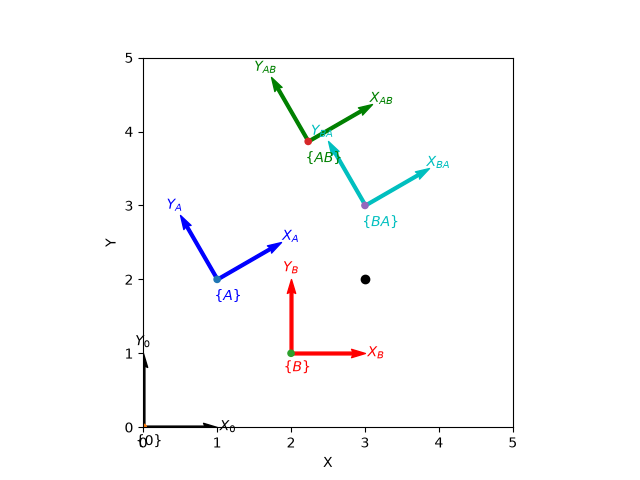

In [22]:
plotvol2([0, 5], new=True); # new plot with both axes from 0 to 5
trplot2(TA, frame="A", color="b");
T0 = transl2(0, 0);
trplot2(T0, frame="0", color="k");  # reference frame
TB = transl2(2, 1)
trplot2(TB, frame="B", color="r");
TAB = TA @ TB
trplot2(TAB, frame="AB", color="g");
TBA = TB @ TA;
trplot2(TBA, frame="BA", color="c"); # note non-commutativity
P = np.array([3, 2]);
plot_point(P, "ko", label="P");

In [23]:
print(TA)
print(P)
np.linalg.inv(TA) @ np.hstack([P, 1]) # coord of P wrt frame {A}

[[   0.866     -0.5        1]
 [     0.5    0.866        2]
 [       0        0        1]]
[3 2]


array([   1.732,       -1,        1])

In [24]:
h2e(np.linalg.inv(TA) @ e2h(P))
# h2e: homogeneous to euclidean
# e2h: euclidean to homogeneous

array([[   1.732],
       [      -1]])

In [25]:
# easiest way of implementing the 2 cells above
homtrans(np.linalg.inv(TA), P)
# homogeneous translation

array([[   1.732],
       [      -1]])

### 2.2.2.2 Rotating a Coordinate Frame


(about an arbitrary point $C$, for example, not just the origin)

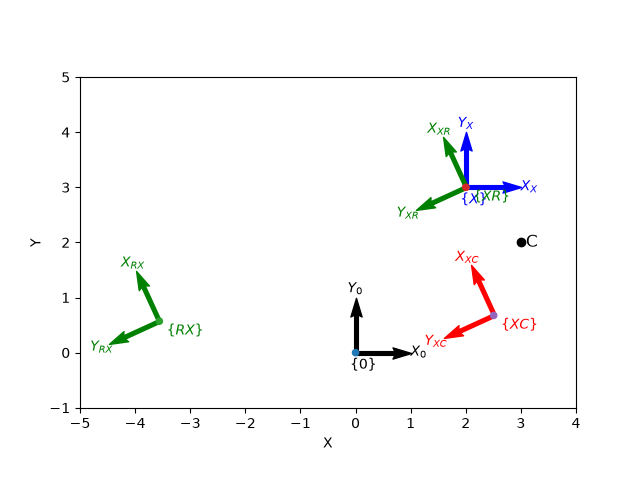

In [26]:
plotvol2([-5, 4, -1, 5], new=True);  # for matplotlib/widget
T0 = transl2(0, 0);
trplot2(T0, frame="0", color="k");
TX = transl2(2, 3);
trplot2(TX, frame="X", color="b");
TR = trot2(2);
trplot2(TR @ TX, frame="RX", color="g");
trplot2(TX @ TR, frame="XR", color="g");
C = np.array([3, 2]);
plot_point(C, "ko", text="C");
TC = transl2(C) @ TR @ transl2(-C) # conjugation!
# from right to left: 
# shift {X} s.t. C is at the centre of the coordinate frame,
# do the rotation,
# do the shift so that C is back at its original position
trplot2(TC @ TX, frame="XC", color="r");

### 2.2.2.3 Matrix exponential for Pose

Below is an example of taking the logarithm and then reversing with the exponential of the $\mathrm{SE}(2)$ matrix `TC`.

In [27]:
TC

array([[ -0.4161,  -0.9093,    6.067],
       [  0.9093,  -0.4161,   0.1044],
       [       0,        0,        1]])

In [28]:
L = linalg.logm(TC)

array([[       0,       -2,        4],
       [       2,        0,       -6],
       [       0,        0,        0]])

In [29]:
S = vexa(L)

array([       4,       -6,        2])

In [30]:
linalg.expm(skewa(S))

array([[ -0.4161,  -0.9093,    6.067],
       [  0.9093,  -0.4161,   0.1044],
       [       0,        0,        1]])

In [31]:
X = skewa([1, 2, 3])

array([[       0,       -3,        1],
       [       3,        0,        2],
       [       0,        0,        0]])

In [32]:
vexa(X)

array([       1,        2,        3])

In general, we can write 
$$\mathbf{T} = e^{[\mathbf{S}]} \in \mathrm{SE}(2)$$
where $\mathbf{S} \in \mathbb{R}^3$ and $[\cdot] : \mathbb{R}^3 \mapsto \mathfrak{se}(2)
\subset \mathbb{R}^{3 \times 3}$.

$[\mathbf{S}]$ is an augmented skew-symmetric matrix.

The vector $\mathbf{S}$ is a twist vector.

### 2.2.2.4 2D Twists

Given any two frames, we can find a rotational centre and a rotation angle that will rotate one into the other.

In [33]:
S = Twist2.UnitRevolute(C)

(2 -3; 1)

The above is a *2D twist vector* $(\mathbf v, \omega)\in\mathbb R^3$ comprising a *moment* $\mathbf v \in\mathbb R^2$ and a scalar $\omega$.
In particular, this is a *unit twist* that describes a rotation of 1 radian about the point `C`.

For the example from 2.2.2.2, we need to rotate 2 radians about the point C, so scale the unit twist and exponentiate:

In [34]:
linalg.expm(skewa(2 * S.S))
# S.S is the twist vector as np array

array([[ -0.4161,  -0.9093,    6.067],
       [  0.9093,  -0.4161,   0.1044],
       [       0,        0,        1]])

In [35]:
S.exp(2) # shorthand for above cell - not np array

  -0.4161   -0.9093    6.067     
   0.9093   -0.4161    0.1044    
   0         0         1         


In [36]:
S.pole # centre of rotation

array([       3,        2])

For pure translation, the rotational centre is at infinity, and therefore a translational (or prismatic) twist is specified only by the direction of motion:

In [37]:
S = Twist2.UnitPrismatic([0, 1])

(0 1; 0)

In [38]:
S.exp(2)

   1         0         0         
   0         1         2         
   0         0         1         


Now for an arbitrary 2D homogeneous tranformation:

In [39]:
T = transl2(3, 4) @ trot2(0.5)

array([[  0.8776,  -0.4794,        3],
       [  0.4794,   0.8776,        4],
       [       0,        0,        1]])

In [40]:
S = Twist2(T)

(3.9372 3.1663; 0.5)

In [41]:
S.w # rotation angle in radians

np.float64(0.5)

In [42]:
S.pole # centre of rotation

array([  -3.166,    3.937])

In [43]:
S.exp(1)

   0.8776   -0.4794    3         
   0.4794    0.8776    4         
   0         0         1         


# 2.3 Working in Three Dimensions (3D)


## 2.3.1 Orientation in Three Dimensions
Rotation in 3D is not commutative. There are many ways to represent rotation, some of which are introduced in each of the following sections.

Right-hand rule for axes: $x$ thumb, $y$ index, $z$ middle.

Right-hand rule for rotation about a vector: with thumb pointing in the direction of the vector, the direction of fingers curling is increasing angle.

### 2.3.1.1 3D Rotation Matrix

A 3D rotation matrix $\mathbf R$ has the same properties as its 2D counterpart:
- The columns are the basis vectors for the rotated 3D frame, and therefore are orthonormal, hence $\mathbf R^{-1}=\mathbf R^\top$.
- $\mathbf R\mathbf v$ is isometric and preserves handedness of the vector $\mathbf v$, so its determinant is $+1$.
- $\mathbf R\in\mathrm{SO}(3)\subset\mathbb R^{3\times 3}$ the special orthogonal group of dimension 3 (which is clearly non-abelian).

The rotation matrices corresponding to rotation of $\theta$ about the axes are:
$$\mathbf{R}_x(\theta) =
\begin{pmatrix}
1 & 0 & 0 \\
0 & \cos\theta & -\sin\theta \\
0 & \sin\theta & \cos\theta
\end{pmatrix}$$
$$\mathbf{R}_y(\theta) =
\begin{pmatrix}
\cos\theta & 0 & \sin\theta \\
0 & 1 & 0 \\
-\sin\theta & 0 & \cos\theta
\end{pmatrix}$$
$$\mathbf{R}_z(\theta) =
\begin{pmatrix}
\cos\theta & -\sin\theta & 0 \\
\sin\theta & \cos\theta & 0 \\
0 & 0 & 1
\end{pmatrix}$$

Below is an example of $\mathbf R_x \left(\frac{\pi} 2\right)$:

In [44]:
R = rotx(pi / 2)

array([[       1,        0,        0],
       [       0,        0,       -1],
       [       0,        1,        0]])

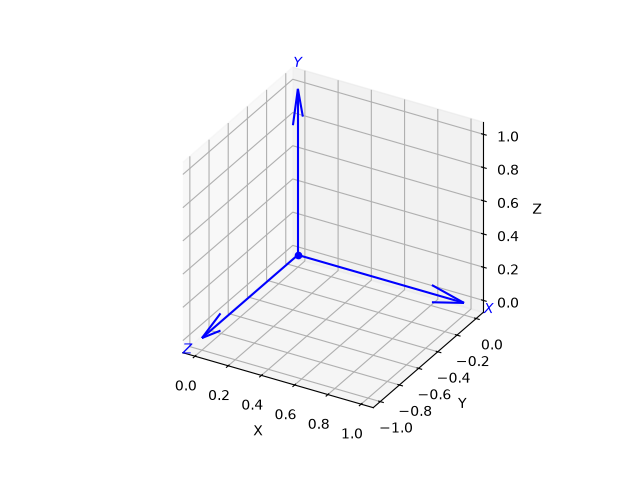

In [45]:
plotvol3(new=True)  # for matplotlib/widget
trplot(R);

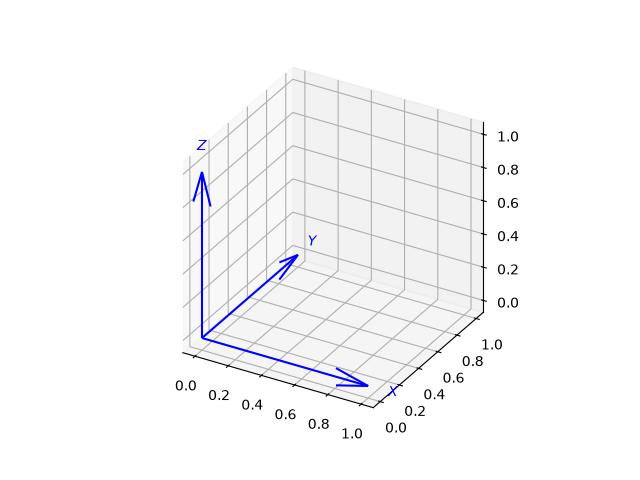

In [46]:
plotvol3(new=True)  # for matplotlib/widget
tranimate(R);
# HTML(tranimate(R, movie=True, dims=1.5))

<div class="alert alert-block alert-info">

**Note:** Robust, portable animation in Jupyter notebooks is challenging.  Here we use an option to `tranimate` that causes it to return the animation as a snippet of HTML5 which is then displayed
```
HTML(tranimate(R, movie=True))
```
If you wish to animate a coordinate frame from a regular Python script use the simpler syntax
```
tranimate(R)
```

</div>

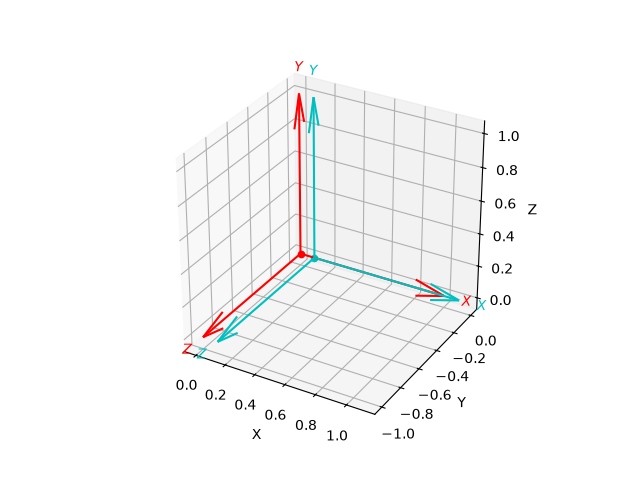

In [47]:
plotvol3(new=True)  # for matplotlib/widget
trplot(R, anaglyph=True) # for 3D glasses lol

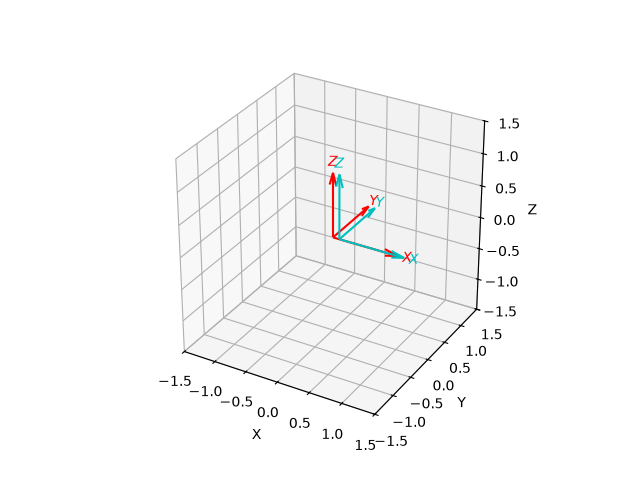

In [48]:
plotvol3(new=True)  # for matplotlib/widget
# HTML(tranimate(R, anaglyph=True, movie=True, dim=1.5))
tranimate(R, anaglyph=True, dim=1.5)

Now apply another rotation, this time about the $y$-axis:

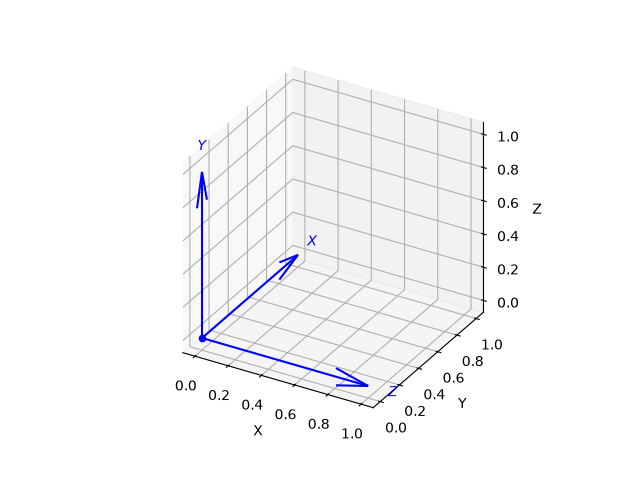

In [49]:
Rxy = rotx(pi / 2) @ roty(pi / 2)
plotvol3(new=True)
trplot(Rxy);
# tranimate(R); # does not do one step at a time

In [50]:
Ryx = roty(pi / 2) @ rotx(pi / 2)

array([[       0,        1,        0],
       [       0,        0,       -1],
       [      -1,        0,        0]])

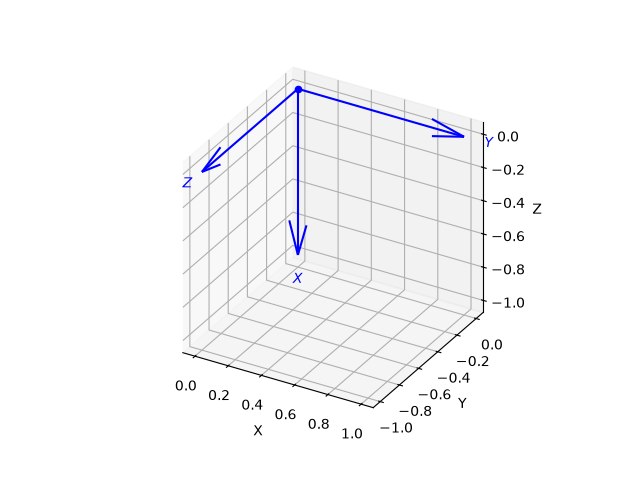

In [51]:
plotvol3(new=True)  # for matplotlib/widget
trplot(Ryx);

### 2.3.1.2 Three-Angle Representations

#### Euler angles


Euler's rotation theorem: any two independent orthonormal coordinate frames can be related by a sequence of rotations (not more than 3) about coordinate axes, with no two successive rotations about the same axis.

There are 12 unique rotation sequences, of which 6 involve (non-successive) repetition of axes, and the other 6 involve all 3 axes.

In mechanical dynamics, "Euler angles" commonly refers to the ZYZ sequence:
$$\mathbf{R}(\phi,\theta,\psi) = \mathbf{R}_z(\phi)\,\mathbf{R}_y(\theta)\,\mathbf{R}_z(\psi)$$
and the Euler angles are written as a vector $\mathbf\Gamma=(\phi,\theta,\psi)\in(\mathbf S^1)^3$.

We can compute the equivalent rotation matrix $\mathbf R$ as follows:

In [52]:
R = rotz(0.1) @ roty(0.2) @ rotz(0.3);

In [53]:
R = eul2r(0.1, 0.2, 0.3)

array([[  0.9021,  -0.3836,   0.1977],
       [  0.3875,   0.9216,  0.01983],
       [ -0.1898,  0.05871,   0.9801]])

The inverse problem is finding the ZYZ Euler angles that correspond to a given rotation matrix:

In [54]:
gamma = tr2eul(R)

array([     0.1,      0.2,      0.3])

If $\theta$ is negative, the rotation matrix is:

In [55]:
R = eul2r(0.1, -0.2, 0.3)

array([[  0.9021,  -0.3836,  -0.1977],
       [  0.3875,   0.9216, -0.01983],
       [  0.1898, -0.05871,   0.9801]])

And the inverse function returns a different set of Euler angles, where $\phi$ and $\psi$ have been offset by $-\pi$:

In [56]:
gamma = tr2eul(R)

array([  -3.042,      0.2,   -2.842])

Though the rotation matrix remains the same:

In [57]:
eul2r(gamma)

array([[  0.9021,  -0.3836,  -0.1977],
       [  0.3875,   0.9216, -0.01983],
       [  0.1898, -0.05871,   0.9801]])

This means that the mapping from a rotation matrix to Euler angles is not unique (2 possibilities). The Python toolbox always returns a positive value for $\theta$.

When $\theta=0$, as follows:

In [58]:
R = eul2r(0.1, 0, 0.3)

array([[  0.9211,  -0.3894,        0],
       [  0.3894,   0.9211,        0],
       [       0,        0,        1]])

The inverse function returns a different array:

In [59]:
tr2eul(R)

array([       0,        0,      0.4])

This is because when $\theta=0$, then the rotation is simply 2 successive rotations about the $z$-axis, and by convention we set $\phi=0$.

When $\theta=0$, this is a singularity.

#### Cardan angles


(aka roll-pitch-yaw, Tait-Bryan, or nautical angles)

We denote roll, pitch, yaw as $\alpha$, $\beta$, and $\gamma$ respectively.

There are two commonly used sequences: ZYX for mobile robots, XYZ for robot manipulators.

For mobile robots, the convention is for $x$-axis of body frame to point in forward direction and $z$-axis to point either up or down.
Then we get 
$$\mathbf R(\alpha,\beta,\gamma)=\mathbf R_z(\gamma)\mathbf R_y(\beta)\mathbf R_x(\alpha)$$
and like Euler angles, we write the angles as a vector $\Gamma=(\alpha,\beta,\gamma)$.

In [60]:
R = rpy2r(0.1, 0.2, 0.3, order="zyx")

array([[  0.9363,  -0.2751,   0.2184],
       [  0.2896,   0.9564, -0.03696],
       [ -0.1987,  0.09784,   0.9752]])

In [61]:
gamma = tr2rpy(R, order="zyx")

array([     0.1,      0.2,      0.3])

For robot grippers, the convention is that the $z$-axis points forward and the $y$-axis is parallel to a line joining the fingertips. So
$$\mathbf R(\alpha,\beta,\gamma)=\mathbf R_x(\gamma)\mathbf R_y(\beta)\mathbf R_z(\alpha).$$

In [62]:
R = rpy2r(0.1, 0.2, 0.3, order="xyz")

array([[  0.9752, -0.09784,   0.1987],
       [  0.1538,   0.9447,  -0.2896],
       [ -0.1593,    0.313,   0.9363]])

In [63]:
gamma = tr2rpy(R, order="xyz")

array([     0.1,      0.2,      0.3])

<div class="alert alert-block alert-warning">

**Warning:** The next cell will launch an interactive tool (using the Swift visualizer) in a new browser tab.  Close the browser tab when you are done with it. 

You might also have to stop the cell from executing, by pressing the stop button for the cell. It may terminate with lots of errors, don't panic.

</div>

In [64]:
if COLAB or not SWIFT:
    print("we can't run this demo from the Colab environment (yet)")
else:
    !tripleangledemo

we can't run this demo from the Colab environment (yet)


The roll-pitch-yaw sequence allows all angles to have arbitrary sign, and it has a singularity when $\beta =\pm \pi/2$.

### 2.3.1.3 Singularities and Gimbal Lock


The problem with all the 3-angle representations is the singularity, as it leads to a loss of a degree of freedom - most famously as gimbal lock on Apollo 11 (also dramatised in the movie Apollo 13). The best we can do is to choose the angle sequence and coordinate system to ensure the singularity occurs for an orientation outside normal operations. Either that, or introduce a fourth parameter.

### 2.3.1.4 Two-Vector Representation


For arm-type robots, by convention the $z$-axis is along the arm direction, called the *approach vector* $\hat{\mathbf a} = (a_x, a_y, a_z)$. The $y$-axis is parallel to the *orientation vector* $\hat{\mathbf o} = (o_x, o_y, o_z)$ connecting the fingertips. These are enough to determine the normal vector $\hat{\mathbf n}:=\hat{\mathbf o}\times\hat{\mathbf a}$ and get the rotation matrix
$$\mathbf R = 
\begin{pmatrix}
n_x & o_x & a_x \\
n_y & o_y & a_y \\
n_z & o_z & a_z 
\end{pmatrix}.$$

In the example below, the robot's gripper is facing downwards:

In [65]:
a = [0, 0, -1]

[0, 0, -1]

In [66]:
o = [1, 1, 0] 

[1, 1, 0]

Note that `o` above is not a unit vector, but `oa2r` will make it so.

In [67]:
R = oa2r(o, a)

array([[ -0.7071,   0.7071,        0],
       [  0.7071,   0.7071,        0],
       [       0,        0,       -1]])

If $\hat{\mathbf o}$ and $\hat{\mathbf a}$ were not orthogonal, we would still calculate $\hat{\mathbf n}$ the same way, but then also a new $\hat{\mathbf o}'=\hat{\mathbf a}\times\hat{\mathbf n}$ to get 3 mutually orthogonal vectors.

Some other conventions:
- camera: optical $z$-axis as $\hat{\mathbf a}$, right side $x$-axis as $\hat{\mathbf n}$
- mobile robot: gravitational acceleration vector $z$-axis as $\hat{\mathbf a}$, heading direction $x$-axis as $\hat{\mathbf n}$

### 2.3.1.5 Rotation about an Arbitrary Vector


Any two coordinate frames are related by a single rotation about some axis in space (!)

In [68]:
R = rpy2r(0.1, 0.2, 0.3);

In [69]:
theta, v = tr2angvec(R)

In [70]:
theta # angle of rotation

0.3655021863566987

In [71]:
v # unit vector parallel to rotation axis (non-unique)

array([  0.1886,   0.5834,     0.79])

A rotation matrix will always have one real eigenvalue at $\lambda =1$ as well as a complex pair $\lambda = \cos\theta\pm i\sin\theta$, and the eigenvector corresponding to $\lambda=1$ is the vector about which rotation occurs:

In [72]:
e, x = np.linalg.eig(R)

In [73]:
e # eigenvalues

array([0.93394439+0.35741835j, 0.93394439-0.35741835j, 1.        +0.j        ])

In [74]:
x # eigenvector columns corresponding to above eigenvalues

array([[-0.69442042+0.j        , -0.69442042-0.j        ,  0.18857511+0.j        ],
       [ 0.07921035+0.56882404j,  0.07921035-0.56882404j,  0.58337798+0.j        ],
       [ 0.10726605-0.42004668j,  0.10726605+0.42004668j,  0.79000605+0.j        ]])

The rotation angle $\theta$ can be seen from the other eigenvalues:

In [75]:
theta = np.angle(e[0])

np.float64(0.3655021863566987)

The inverse problem, getting the rotation matrix from an angle and vector, is achieved using Rodrigues' rotation formula:
$$
\mathbf{R} = \mathbf{1}_{3\times 3} + \sin\theta[\hat{\mathbf{v}}]_\times + (1-\cos\theta)[\hat{\mathbf{v}}]_\times^2
$$

TODO: derive this (split into parallel and perpendicular components & use some identity for unit vectors in general)

In [76]:
R = angvec2r(0.3, [1, 0, 0])

array([[       1,        0,        0],
       [       0,   0.9553,  -0.2955],
       [       0,   0.2955,   0.9553]])

The Euler-Rodrigues formula is a variation that directly transforms a coordinate vector $x$ to where it is after rotation:
$$
x' = \mathbf R(\theta,\hat{\mathbf v})\mathbf x
=\mathbf x + 2(\mathbf\omega\times \mathbf x)

+ 2s(\mathbf\omega\times(\mathbf\omega\times \mathbf x))
$$
where $s = \cos(\theta/2)$ and $\mathbf\omega=\hat{\mathbf v}\sin(\theta/2)$. Collectively, $(s,\mathbf\omega) \in \mathbb R^4$ are known as the *Euler parameters* of the rotation. This is in fact a unit quaternion.

Due to the unit norm requirement, the 4 numbers parameterising the angle-axis representation can be packed into a vector $\mathbf v\in\mathbb R^3$ where the rotation angle is some function of the magnitude $\|\mathbf v\|$. This leads to several common 3-parameter representations. However, the direction when $\theta=0$ is not defined and would need to be dealt with explicitly.

### 2.3.1.6 Matrix Exponential for Rotation


In [77]:
R = rotx(0.3)

array([[       1,        0,        0],
       [       0,   0.9553,  -0.2955],
       [       0,   0.2955,   0.9553]])

In [78]:
L = linalg.logm(R)

array([[       0,        0,        0],
       [       0,        0,     -0.3],
       [       0,      0.3,        0]])

In [79]:
S = vex(L)

array([     0.3,        0,        0])

In [80]:
L = trlog(R); # computationally efficient

In [81]:
linalg.expm(L)

array([[       1,        0,        0],
       [       0,   0.9553,  -0.2955],
       [       0,   0.2955,   0.9553]])

In [82]:
trexp(L); # computationally efficient

Note: the exponential of a skew-symmetric matrix is always a rotation matrix.

In [83]:
linalg.expm(skew(S))

array([[       1,        0,        0],
       [       0,   0.9553,  -0.2955],
       [       0,   0.2955,   0.9553]])

In [84]:
R = rotx(0.3);

In [85]:
R = linalg.expm(0.3 * skew([1, 0, 0]));

In [86]:
X = skew([1, 2, 3])

array([[ 0, -3,  2],
       [ 3,  0, -1],
       [-2,  1,  0]])

In [87]:
vex(X)

array([       1,        2,        3])

In general, we can write 
$$\mathbf{R} = e^{\theta[\hat{\mathbf{\omega}}]_\times} \in \mathrm{SO}(3)$$
where $\theta$ is the rotation angle, $\hat{\boldsymbol{\omega}}$ is a unit vector parallel to the rotation axis, and $[\cdot]_{\times} : \mathbb{R}^3 \mapsto \mathfrak{so}(3) \subset \mathbb{R}^{3 \times 3}$. Since $\theta[\hat{\boldsymbol{\omega}}]_{\times} = [\theta\hat{\boldsymbol{\omega}}]_{\times}$, we can completely describe the rotation by the vector $\theta\hat{\boldsymbol{\omega}}\in\mathbb R^3$, known as exponential coordinates.

Rodrigues' rotation formula is a computationally efficient method to calculate matrix exponential in the special case where the argument is skew-symmetric.

### 2.3.1.7 Unit Quaternions


Quaternions: 
$\breve q := s+v_xi+v_yj+v_zk\in\mathbb H$
where the orthogonal complex numbers $i$, $j$ and $k$ are defined such that $i^2=j^2=k^2=ijk=-1$.
More commonly now as an ordered pair $\breve q=(s,\mathbf v)$ or sometimes written $s + \mathbf v$, where $s\in\mathbb R$ and $\mathbf v\in\mathbb R^3$.

In this book, written as $$\breve q=s\langle v_x, v_y, v_z\rangle\in\mathbb H.$$

Quaternions form a vector space, with elementwise addition and scalar multiplication.
Some other operations are
- Conjugation (inverse): $\breve{q}^* = s\langle -v_x, -v_y, -v_z \rangle \in \mathbb{H}$.
- Quaternion / Hamilton product (not commutative): $\breve{q}_1 \circ \breve{q}_2 = s_1 s_2 - \mathbf{v}_1 \cdot \mathbf{v}_2 \langle s_1 \mathbf{v}_2 + s_2 \mathbf{v}_1 + \mathbf{v}_1 \times \mathbf{v}_2 \rangle \in \mathbb{H}$
- Inner product: $\breve{q}_1 \cdot \breve{q}_2 = s_1 s_2 + v_{x_1} v_{x_2} + v_{y_1} v_{y_2} + v_{z_1} v_{z_2} \in \mathbb{R}$
- Magnitude: $\|\breve{q}\| = \sqrt{\breve{q} \cdot \breve{q}} = \sqrt{s^2 + v_x^2 + v_y^2 + v_z^2} \in \mathbb{R}.$

A *pure quaternion* has $s=0$.

A *unit quaternion* $\mathring q$ has magnitude $\|\breve{q}\|=1$. 
They can be considered as a rotation of $\theta$ about the unit vector $\hat{\mathbf v}$ where
$$\mathring q=\cos\frac\theta 2\left\langle\hat{\mathbf v}\sin\frac\theta 2\right\rangle \in S^3,$$
similar to the angle-axis representation.
Also, $\mathring q = -\mathring q$ (double mapping).

Some really cool resources!
- [Hamish Todd doing a fun VR demo](https://www.youtube.com/watch?v=g5XWNwBJWeY)
- [3B1B x Ben Eater interactive](https://eater.net/quaternions) - fine grained control over each numerical component

In [9]:
q = UnitQuaternion(rpy2r(0.1, 0.2, 0.3))

 0.9833 <<  0.0343,  0.1060,  0.1436 >>


In [89]:
q = q * q; # quaternion multiplication

In [90]:
q.inv()

 0.9339 << -0.0674, -0.2085, -0.2824 >>


In [91]:
q * q.inv()

 1.0000 <<  0.0000,  0.0000,  0.0000 >>


In [92]:
q / q # sugar for multiplying by inverse above

 1.0000 <<  0.0000,  0.0000,  0.0000 >>


In [93]:
q.R # convert to rotation matrix

array([[  0.7536,  -0.4993,   0.4275],
       [  0.5555,   0.8315, -0.008145],
       [ -0.3514,   0.2436,    0.904]])

In [94]:
q * [1, 0, 0] # rotate a vector by q (matrix-vec mult)

array([  0.7536,   0.5555,  -0.3514])

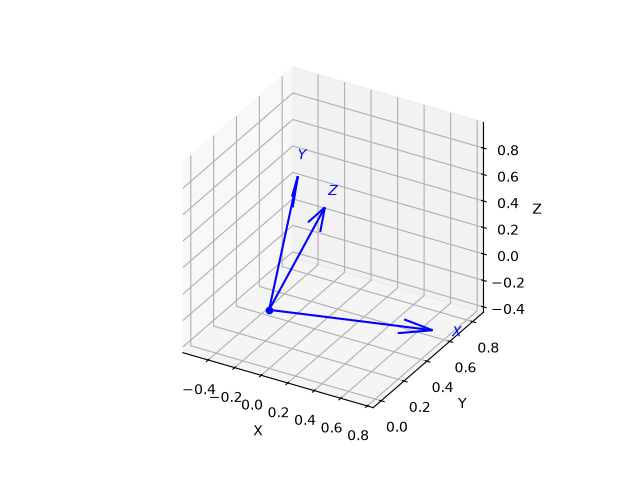

In [95]:
plotvol3(new=True)  # for matplotlib/widget
q.plot();

Since the scalar can be calculated by $s=\pm(1-v_x^2-v_x^2-v_z^2)^{1/2}$, we can store just the vector part, resolving the sign ambiguity by ensuring $s$ is positive before storing the vector by convention. This is often used in optimization problems.

## 2.3.2 Pose in Three Dimensions


### 2.3.2.1 Homogeneous Transformation Matrix


Similar to the 2D case, arbitrary transformations can be represented by a $4\times 4$ homogeneous matrix $\mathbf {}^{A}\mathbf T_{B}=T\in\mathrm{SE}(3)\subset\mathbb R^{4\times 4}$, where 
$$
{}^{A}\tilde{\mathbf p}=
\begin{pmatrix}
{}^{A}x\\
{}^{A}y\\
{}^{A}z\\
1
\end{pmatrix}
=
\begin{pmatrix}
{}^{A}\mathbf{R}_{B} & {}^{A}\mathbf{t}_{B}\\
\mathbf{0}_{1\times 3} & 1
\end{pmatrix}
\begin{pmatrix}
{}^{B}x\\
{}^{B}y\\
{}^{B}z\\
1
\end{pmatrix}
= {}^{A}\mathbf T_{B} \, {}^{B}\tilde{\mathbf p}
$$

In [ ]:
# translate along x-axis, then rotate about x-axis,
# then translate along original x-axis (now y-axis)
T = transl(2, 0, 0) @ trotx(pi / 2) @ transl(0, 1, 0)

array([[       1,        0,        0,        2],
       [       0,        0,       -1,        0],
       [       0,        1,        0,        1],
       [       0,        0,        0,        1]])

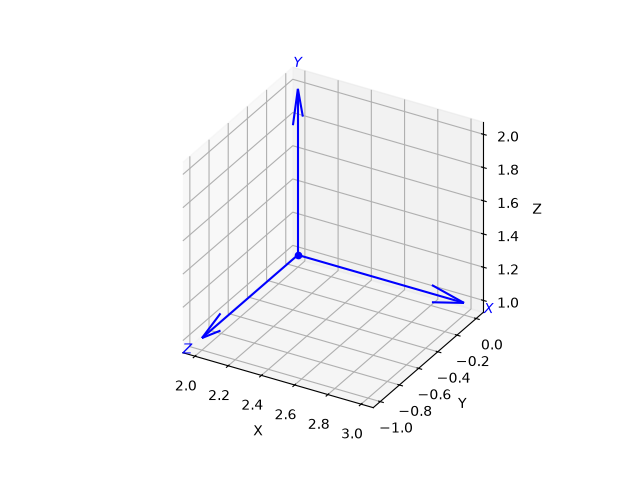

In [97]:
plotvol3(new=True)  # for matplotlib/widget
trplot(T);

In [ ]:
t2r(T) # rotation component R

array([[       1,        0,        0],
       [       0,        0,       -1],
       [       0,        1,        0]])

In [ ]:
transl(T) # translation component t

array([       2,        0,        1])

### 2.3.2.2 Matrix exponential for Pose


In general, we can write 
$$\mathbf T=e^{[\mathbf S]}\in\mathrm{SE}(3)$$
where the *twist vector* $\mathbf S\in\mathbb R^6$ and $[\cdot]:\mathbb R^6\mapsto\mathfrak{se}(3)\subset\mathbb R^{4\times4}$.

In [100]:
T = transl(2, 3, 4) @ trotx(0.3)

array([[       1,        0,        0,        2],
       [       0,   0.9553,  -0.2955,        3],
       [       0,   0.2955,   0.9553,        4],
       [       0,        0,        0,        1]])

In [101]:
L = linalg.logm(T)

array([[       0,        0,        0,        2],
       [       0,        0,     -0.3,    3.577],
       [       0,      0.3,        0,     3.52],
       [       0,        0,        0,        0]])

In [102]:
S = vexa(L)

array([       2,    3.577,     3.52,      0.3,        0,        0])

In [103]:
linalg.expm(skewa(S))

array([[       1,        0,        0,        2],
       [       0,   0.9553,  -0.2955,        3],
       [       0,   0.2955,   0.9553,        4],
       [       0,        0,        0,        1]])

In [104]:
X = skewa([1, 2, 3, 4, 5, 6])

array([[       0,       -6,        5,        1],
       [       6,        0,       -4,        2],
       [      -5,        4,        0,        3],
       [       0,        0,        0,        0]])

In [105]:
vexa(X)

array([       1,        2,        3,        4,        5,        6])

### 2.3.2.3 3D Twists


Given any two poses in 3D, we can find an axis and moment around that axis to map one to the other. 
(For pure translation, the rotation is about a screw axis at infinity.)

We represent this *screw* motion by a twist vector $(\mathbf v, \mathbf\omega)\in\mathbb R^6$ comprising the *moment* $\mathbf v\in\mathbb R^3$ and the *vector* $\mathbf w\in\mathbb R^3$ parallel to the screw axis.

The *pitch* is the ratio of distance along the axis to the rotation about the axis.

A *unit twist* describes a rotation of 1 rad about some axis, eg below `S` is unit twist about the $x$-axis.

In [106]:
S = Twist3.UnitRevolute([1, 0, 0], [0, 0, 0])

(0 0 0; 1 0 0)

In [107]:
linalg.expm(0.3 * skewa(S.S));  # different to book, see §2.2.1.2

In [108]:
S.exp(0.3)

   1         0         0         0         
   0         0.9553   -0.2955    0         
   0         0.2955    0.9553    0         
   0         0         0         1         


Screw with axis parallel to $z$-axis

In [109]:
S = Twist3.UnitRevolute([0, 0, 1], [2, 3, 2], 0.5)

(3 -2 0.5; 0 0 1)

In [110]:
X = transl(3, 4, -4);

In [113]:
for theta in np.arange(0, 15, 0.3):
  trplot(S.exp(theta).A @ X, style="rviz", width=2)

L = S.line()
L.plot('k:', linewidth=2);


Axes3D(0.22375,0.11;0.5775x0.77)


Translational (prismatic) twist in $y$-direction

In [114]:
S = Twist3.UnitPrismatic([0, 1, 0])

(0 1 0; 0 0 0)

In [115]:
S.exp(2)

   1         0         0         0         
   0         1         0         2         
   0         0         1         0         
   0         0         0         1         


Arbitrary $\mathrm{SE}(3)$ matrix

In [116]:
T = transl(1, 2, 3) @ eul2tr(0.3, 0.4, 0.5);
S = Twist3(T)

(1.1204 1.6446 3.1778; 0.041006 0.4087 0.78907)

In [ ]:
S.w # axis

array([ 0.04101,   0.4087,   0.7891])

In [118]:
S.pole # passes through this point

array([0.001138,   0.8473,  -0.4389])

In [ ]:
S.pitch

np.float64(4.07608892668216)

In [120]:
S.theta # rotation about the axis

0.8895797456112914

One could also represent pose in 3D as:
- vector-quaternion pair $(\mathbf t, \mathring q)\in\mathbb R^3\times S^3$ (requires 7 numbers, singularity free, easy to compound)
- unit dual quaternion (8 numbers, easy to compound and normalize, but "no real useful computational advantage over matrix methods")

# 2.4 Advanced Topics


Below, $N$ is the number of parameters and $N_{\mathrm{min}}$ is the minimum number of parameters stored. Although the matrix representations are least efficient, their multiplication is very efficient.

![table-21-pose-parameters.png](table-21-pose-parameters.png)

## 2.4.5 Distance Between Orientations


Distance metrics: there exist several for both rotation matrices and quaternions.

In [3]:
UnitQuaternion.Rx(pi / 2).angdist(UnitQuaternion.Rz(-pi / 2))

1.0471975511965976

## 2.4.6 Normalization


By definition, a rotation matrix has determinant one:

In [4]:
R = np.eye(3,3);
np.linalg.det(R) - 1

np.float64(0.0)

but repeated multiplication introduces floating-point arithmetic error:

In [5]:
for i in range(100):
  R = R @ rpy2r(0.2, 0.3, 0.4);
np.linalg.det(R) - 1

np.float64(5.773159728050814e-15)

In the toolbox, normalization is implemented by:

In [6]:
R = trnorm(R);

In [7]:
np.linalg.det(R) - 1

np.float64(2.220446049250313e-16)

Arithmetic issues also occur with unit quaternion multiplication, but this is easier to fix compared to matrices (just divide all elements by the norm).

In [12]:
q = q.unit()

 0.9833 <<  0.0343,  0.1060,  0.1436 >>


In [ ]:
# T = T1 @ T2
# q = q1 @ q2

Normalization does not need to be performed after every operation - it is computationally expensive. But recommended for situations where one transform is repeatedly updated.

## 2.4.8 More About Twists


Chasles' theorem: Any displacement of a body in space can be accomplished by means of a rotation of the body about a unique line in space accompanied by a translation of the body parallel to that line.

This forms the foundation of screw theory.

In [ ]:
S = Twist3.UnitRevolute([1, 0, 0], [0, 0, 0])

In [ ]:
S.S
S.v
S.w

In [ ]:
S.skewa()

In [ ]:
trexp(0.3 * S.skewa())

In [ ]:
S.exp(0.3)

In [ ]:
S2 = S * S
S2.printline(orient="angvec", unit="rad")

In [ ]:
line = S.line()

In [ ]:
plotvol3([-5, 5], new=True)  # setup volume in which to display the line
line.plot("k:", linewidth=2);

In [ ]:
T = transl(1, 2, 3) @ eul2tr(0.3, 0.4, 0.5);
S = Twist3(T)

In [ ]:
S / S.theta

In [ ]:
S.unit();

In [ ]:
S.exp(0)

In [ ]:
S.exp(1)

In [ ]:
S.exp(0.5)

<div class="alert alert-block alert-warning">

**Warning:** The next cell will launch an interactive tool (using the Swift visualizer) in a new browser tab.  Close the browser tab when you are done with it. 

You might also have to stop the cell from executing, by pressing the stop button for the cell. It may terminate with lots of errors, don't panic.

</div>

In [ ]:
if COLAB or not SWIFT:
    print("we can't run this demo from the Colab environment (yet)")
else:
    !twistdemo

# 2.5 Using the Toolbox


In [1]:
from spatialmath.base import *

In [2]:
from spatialmath import *

In [3]:
R = rotx(0.3)  # create SO(3) matrix as NumPy array
type(R)
R = SO3.Rx(0.3)  # create SO3 object
type(R)

spatialmath.pose3d.SO3

In [ ]:
R.A # the equivalent numpy array

array([[ 1.        ,  0.        ,  0.        ],
       [ 0.        ,  0.95533649, -0.29552021],
       [ 0.        ,  0.29552021,  0.95533649]])

In [5]:
R = SO3(rotx(0.3));                   # convert an SO(3) matrix
R = SO3.Rz(0.3);                      # rotation about z-axis
R = SO3.RPY(10, 20, 30, unit="deg");  # from roll-pitch-yaw angles
R = SO3.AngleAxis(0.3, (1, 0, 0));    # from angle and rotation axis
R = SO3.EulerVec((0.3, 0, 0));        # from an Euler vector

In [6]:
R.rpy();        # convert to roll-pitch-yaw angles
R.eul();        # convert to Euler angles
R.printline();  # compact single-line print

 rpy/zyx = 17.2°, 0°, 0°


In [ ]:
# polymorphism
R = SO3.RPY(10, 20, 30, unit="deg");             # create an SO(3) rotation
T = SE3.RPY(10, 20, 30, unit="deg");             # create a purely rotational SE(3)
S = Twist3.RPY(10, 20, 30, unit="deg");          # create a purely rotational twist
q = UnitQuaternion.RPY(10, 20, 30, unit="deg");  # create a unit quaternion

In [8]:
TA = SE2(1, 2) * SE2(30, unit="deg");
type(TA)

spatialmath.pose2d.SE2

In [9]:
TA

   0.866    -0.5       1         
   0.5       0.866     2         
   0         0         1         


In [10]:
TA = SE2(1, 2, 30, unit="deg");

In [11]:
TA.R
TA.t

array([1., 2.])

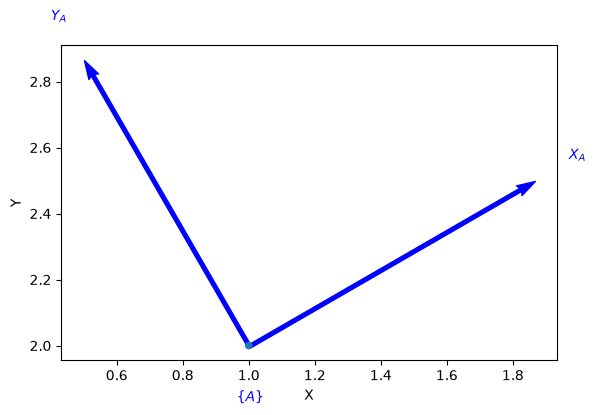

In [12]:
plotvol2(new=True)  # for matplotlib/widget
TA.plot(frame="A", color="b");

In [13]:
TA.printline()

t = 1, 2; 30°


In [14]:
P = [3, 2];
TA.inv() * P

array([[ 1.73205081],
       [-1.        ]])

Below is an example of how one could represent a set of poses along a trajectory, with multiple poses stored together.

In [19]:
R = SO3.Rx(np.linspace(0, 1, 5));
print(len(R)) # all inherit from Python list class
R[3]

5


   1         0         0         
   0         0.7317   -0.6816    
   0         0.6816    0.7317    


In [18]:
R * [1, 2, 3]

array([[ 1.        ,  1.        ,  1.        ,  1.        ,  1.        ],
       [ 2.        ,  1.19561297,  0.31688851, -0.58153854, -1.44380834],
       [ 3.        ,  3.40154518,  3.59159876,  3.55834413,  3.30384889]])